In [1]:
%%capture _analysis
# Re-run the analysis notebook; every number in this report comes from its variables.
%run "2_acuracia_sa23z.ipynb"

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix

plt.close("all")
%config InlineBackend.figure_formats = ["svg"]

# Level-2 classes kept in the assessment: English name and MapBiomas (Portuguese) name.
CLASSES = {
    3:  ("Forest Formation",      "Formação Florestal"),
    4:  ("Savanna Formation",     "Formação Savânica"),
    5:  ("Mangrove",              "Mangue"),
    11: ("Wetland",               "Campo Alagado e Área Pantanosa"),
    12: ("Grassland",             "Formação Campestre"),
    15: ("Pasture",               "Pastagem"),
    18: ("Agriculture",           "Agricultura"),
    21: ("Mosaic of Uses",        "Mosaico de Usos"),
    23: ("Beach and Dune",        "Praia e Duna"),
    24: ("Urban Area",            "Área Urbanizada"),
    33: ("River, Lake and Ocean", "Rio, Lago e Oceano"),
}

# Sample-count confusion matrix: rows = map (classification), columns = reference.
labels = np.array(sorted(CLASSES))
assert set(np.unique(np.concatenate([y_true, y_pred]))) == set(labels)
cm = confusion_matrix(y_true, y_pred, labels=labels).T
n = cm.sum()
diag = np.diag(cm)
n_map, n_ref = cm.sum(axis=1), cm.sum(axis=0)

users = diag / n_map
producers = diag / n_ref
overall_accuracy = diag.sum() / n
p_map, p_ref, p_diag = n_map / n, n_ref / n, diag / n
quantity = np.abs(p_ref - p_map).sum() / 2
allocation = (2 * np.minimum(p_map - p_diag, p_ref - p_diag)).sum() / 2
kappa = cohen_kappa_score(y_true, y_pred)

# Supplementary figures from the analysis notebook.
area_weighted_accuracy = AG                       # last value of AG: area-weighted section
no_training = df_acc["AMOSTRAS"] != "Treinamento"
n_training = int((~no_training).sum())                       # among the 655 analysed
n_training_raw = int((pd.read_csv(path_acc)["AMOSTRAS"] == "Treinamento").sum())  # among all 712
accuracy_no_training = accuracy_score(df_acc.loc[no_training, "reference"],
                                      df_acc.loc[no_training, "classification"])

# National figures reported by MapBiomas (2023), as cited in the article.
BRAZIL = {"overall_accuracy": 0.858, "overall_error": 0.142, "quantity": 0.048, "allocation": 0.094}

pct = lambda x, d=1: f"{100 * x:.{d}f}%"
idx = {c: i for i, c in enumerate(labels)}

In [3]:
# The text of this report quotes the values below. Stop the build if the analysis changes.
assert (len(df_acc), n) == (655, 655) and len(labels) == 11
assert round(overall_accuracy, 3) == 0.716 and round(1 - overall_accuracy, 3) == 0.284
assert round(quantity, 3) == 0.076 and round(allocation, 3) == 0.208
assert round(kappa, 2) == 0.62
assert n - diag.sum() == 186
assert (n_map[idx[5]], n_ref[idx[5]], diag[idx[5]], cm[idx[5], idx[3]]) == (32, 15, 14, 18)
assert (n_map[idx[23]], diag[idx[23]]) == (14, 14)
assert (n_map[idx[21]], n_ref[idx[21]], diag[idx[21]]) == (18, 10, 10)
assert (n_map[idx[12]], n_ref[idx[12]], diag[idx[12]]) == (10, 25, 1)
assert [cm[idx[k], idx[12]] for k in (11, 15, 4)] == [7, 6, 4]
assert n_map[idx[5]] - diag[idx[5]] == cm[idx[5], idx[3]]
assert (n_training_raw, n_training) == (82, 69)
assert round(accuracy_no_training, 3) == 0.720
assert round(area_weighted_accuracy, 3) == 0.756

In [4]:
display(HTML("""
<style>
:root { --ink:#0b0b0b; --ink-2:#52514e; --rule:#d9d8d3; --accent:#2a78d6; --paper:#ffffff; }
html, body { background: var(--paper) !important; }
body, .jp-Notebook, .jp-RenderedHTMLCommon {
  font-family: "Charter", "Bitstream Charter", "Georgia", "DejaVu Serif", serif !important;
  color: var(--ink) !important; font-size: 10.5pt !important; line-height: 1.5 !important;
}
.jp-Notebook { max-width: 168mm; margin: 0 auto !important; padding: 0 !important; }
.jp-Cell, .jp-Cell-outputWrapper, .jp-OutputArea, .jp-OutputArea-child, .jp-OutputArea-output,
.jp-RenderedHTMLCommon, .jp-MarkdownOutput { padding: 0 !important; margin: 0 !important; overflow: visible !important; }
.jp-InputPrompt, .jp-OutputPrompt, .jp-Collapser { display: none !important; }
.jp-OutputArea-child { display: block !important; }
.jp-RenderedHTMLCommon p { margin: 0 0 0.6em !important; text-align: justify; hyphens: auto; }
.jp-RenderedHTMLCommon h1, .jp-RenderedHTMLCommon h2, .jp-RenderedHTMLCommon h3 {
  font-family: "Inter", "Helvetica Neue", Arial, sans-serif !important; color: var(--ink) !important;
  break-after: avoid; }
.jp-RenderedHTMLCommon h1 { font-size: 17pt !important; line-height: 1.25 !important; margin: 0 0 0.3em !important; font-weight: 700; }
.jp-RenderedHTMLCommon h2 { font-size: 12pt !important; margin: 1.3em 0 0.4em !important; font-weight: 650;
  border-bottom: 1px solid var(--rule); padding-bottom: 2px; }
.jp-RenderedHTMLCommon h3 { font-size: 10.5pt !important; margin: 1em 0 0.3em !important; font-weight: 600; }
.jp-RenderedHTMLCommon a { color: var(--accent) !important; text-decoration: none; }
.jp-RenderedHTMLCommon .anchor-link { display: none !important; }
.jp-RenderedHTMLCommon code { font-size: 9pt; background: #f2f1ee; padding: 0 3px; border-radius: 3px; }
.jp-RenderedHTMLCommon ul, .jp-RenderedHTMLCommon ol { margin: 0 0 0.6em 1.2em !important; }
.jp-RenderedHTMLCommon li { margin: 0 0 0.2em !important; }
.subtitle { font-family: "Inter", Arial, sans-serif; color: var(--ink-2); font-size: 10.5pt; margin-bottom: 1em; }
.authors { font-family: "Inter", Arial, sans-serif; font-size: 9.5pt; line-height: 1.45; margin-bottom: 1em; }
.authors .aff { color: var(--ink-2); }
.note { font-family: "Inter", Arial, sans-serif; font-size: 8.5pt; color: var(--ink-2);
  border-left: 3px solid var(--accent); background: #f5f8fd; padding: 6px 10px; margin: 0 0 1em; }
.abstract { border-top: 1px solid var(--rule); border-bottom: 1px solid var(--rule); padding: 8px 0 4px; margin-bottom: 1em; }
.abstract p { font-size: 10pt; }
.caption { font-family: "Inter", Arial, sans-serif; font-size: 8.5pt; color: var(--ink-2); margin: 0.9em 0 0.3em; break-after: avoid; }
.caption b { color: var(--ink); }
.source { font-family: "Inter", Arial, sans-serif; font-size: 7.5pt; color: var(--ink-2); margin: 0.2em 0 1em; }
.jp-RenderedHTMLCommon table.report-table { border-collapse: collapse !important; table-layout: auto !important;
  font-family: "Inter", Arial, sans-serif; font-size: 8pt !important; font-variant-numeric: tabular-nums;
  margin: 0 !important; width: 100%; break-inside: avoid; }
.jp-RenderedHTMLCommon .report-table th, .jp-RenderedHTMLCommon .report-table td {
  padding: 2.5px 5px !important; border: none; text-align: right !important; white-space: nowrap;
  line-height: 1.3 !important; max-width: none !important; }
.jp-RenderedHTMLCommon .report-table .left { text-align: left !important; white-space: normal; }
.jp-RenderedHTMLCommon .report-table .group { text-align: center !important; }
.jp-RenderedHTMLCommon .report-table tbody tr:hover { background: inherit; }
.report-table thead th { border-bottom: 1px solid var(--ink); font-weight: 600; vertical-align: bottom; }
.report-table tbody tr:last-child td, .report-table tbody tr:last-child th { border-bottom: 1px solid var(--ink); }
.report-table tbody tr:nth-child(even) { background: #f7f7f5; }
.report-table .pt { color: var(--ink-2); }
.report-table .diag { background: #dce9fa; font-weight: 600; }
.report-table .total { font-weight: 600; border-top: 1px solid var(--ink-2); }
.report-table thead .group { border-bottom: 1px solid var(--rule) !important; }
figure, .jp-OutputArea-output svg { break-inside: avoid; }
.jp-RenderedSVG, .jp-RenderedImage { text-align: center; padding: 0 !important; }
.jp-RenderedSVG svg { max-width: 100%; height: auto; }
.refs p { font-size: 8.5pt; text-align: left; margin-bottom: 0.4em !important; padding-left: 1.5em; text-indent: -1.5em; }
.pagebreak { break-before: page; }
</style>
"""))

# Accuracy of MapBiomas Collection 8 land use and land cover classification in the São Luís intermediate region, Brazil

<div class="subtitle">Companion report — a reproducible English summary of Rocha et al. (2025), <i>Geonordeste</i>, 36(2), 121–139</div>

<div class="authors">
Thomas Victor de Sousa Malheiros Rocha · Sérgio Souza Costa · Luís Fernando Cirqueira da Silva Correia · Denilson da Silva Bezerra<br>
<span class="aff">Universidade Federal do Maranhão (UFMA), São Luís, Brazil · Contact: sergio.costa@ufma.br</span>
</div>

<div class="note">
This report is built from <code>3_report_en.ipynb</code>, which re-runs the analysis notebook <code>2_acuracia_sa23z.ipynb</code>
on the data in the repository <a href="https://github.com/LambdaGeo/acuracia-slz">github.com/LambdaGeo/acuracia-slz</a>.
Every number, table and figure is computed when the report is built. It summarizes the peer-reviewed article,
published in Portuguese: <a href="https://doi.org/10.33360/geonordeste.v36i.21680">doi:10.33360/geonordeste.v36i.21680</a>.
Please cite the article.
</div>

<div class="abstract">

**Abstract.** MapBiomas publishes annual land use and land cover maps for Brazil together with national accuracy statistics, but these statistics do not cover several classes that matter on the coast of Maranhão, such as Mangrove, Apicum (hypersaline tidal flat) and Beach and Dune. We assessed the accuracy of MapBiomas Collection 8 for 2022 at legend level 2 in chart group SA-23-Z, which covers about 72% of the São Luís intermediate region. Of the 712 MapBiomas validation samples in the chart group, 655 samples in 11 classes remained after removing classes with too few samples. Based on sample counts, overall accuracy was 71.6%. The overall error of 28.4% splits into 7.6% quantity disagreement and 20.8% allocation disagreement, against 9.4% allocation disagreement nationally. Cohen's Kappa was 0.62, which corresponds to substantial agreement on the Landis and Koch scale. Beach and Dune reached 100% user's and producer's accuracy. Mangrove had a high producer's accuracy (93%) but a 56% commission error: all 18 of its commission errors were Forest Formation samples mapped as Mangrove. Grassland was the least accurate class. Apicum could not be assessed because it had only three reference samples.

**Keywords:** MapBiomas; accuracy assessment; land use and land cover; remote sensing; Maranhão.

</div>

## 1. Introduction

Land use and land cover maps underpin environmental monitoring, territorial planning and conservation. In Brazil, the MapBiomas project produces annual maps from Landsat imagery, classified with random forest in Google Earth Engine, for every year since 1985 (Souza et al., 2020). MapBiomas also releases its validation samples and accuracy statistics. The statistics are reported for the country and for each biome, and they leave out several level-2 classes, including Mangrove, Apicum, Beach and Dune, Mining and Urban Area.

These classes are central to the São Luís intermediate region, in the north of the state of Maranhão. The region has 73 municipalities and about 70,800 km², and its coast holds some of the largest mangrove and dune areas in Brazil, including the Lençóis Maranhenses. This study assesses the accuracy of MapBiomas level-2 classes for this region, so that local users know how far the maps can be trusted there.

## 2. Data and methods

### 2.1 Reference samples

MapBiomas assesses accuracy with about 75,000 spatially independent samples distributed over Brazil and stratified by IBGE chart groups and slope classes. Each sample was labelled by three interpreters, with majority voting and a fourth reviewer for ties (Parente et al., 2021). Sample sizes per chart group were set for a maximum margin of error of 5% at a 95% confidence level. To keep that design intact, the analysis uses one whole chart group rather than clipping samples to the region boundary: SA-23-Z, which covers about 72% of the São Luís intermediate region and contains 712 samples.

The MapBiomas Google Earth Engine code was adapted only to restrict the export to SA-23-Z (`1_export_gee_input.js`). It returns, for each sample, the reference label and the Collection 8 classification for 2022.

### 2.2 Pre-processing

Class codes were converted and aggregated to legend level 2 with the MapBiomas reconciliation rules. Classes that could not be assessed reliably were then removed: classes with fewer than 10 reference samples (Silviculture, Apicum and Other Non-Vegetated Areas), Floodable Forest, which had no reference samples, and Herbaceous Sandbank Vegetation (Restinga Herbácea), which had reference samples but was never mapped. As in the MapBiomas code, only classes present in both the classification and the reference were kept. This left **655 samples in 11 classes**.

### 2.3 Accuracy metrics

From the confusion matrix we computed overall accuracy; user's accuracy and its complement, the commission error; and producer's accuracy and its complement, the omission error. Following MapBiomas, the overall error was split into quantity disagreement and allocation disagreement (Pontius and Millones, 2011). We also report Cohen's Kappa, interpreted with the scale of Landis and Koch (1977), despite its known limitations, for comparison with other studies. All metrics in Sections 3.1 to 3.3 are computed from sample counts, without area weighting.

## 3. Results

### 3.1 Per-class accuracy

Forest Formation dominates the samples (282 of 655 reference samples) and is classified well, with user's and producer's accuracies near 80% (Table 1). Among the coastal classes that MapBiomas does not report, Beach and Dune was classified without errors, and Mangrove was rarely missed (one omission out of 15 reference samples) but often over-mapped: 18 of the 32 samples mapped as Mangrove were Forest Formation in the reference. Mosaic of Uses shows the same pattern, with every reference sample found but 8 of 18 mapped samples belonging to other classes. Grassland was the weakest class: only 1 of its 25 reference samples was mapped correctly.

In [5]:
rows = []
for i, c in enumerate(labels):
    en, pt = CLASSES[c]
    rows.append(
        f"<tr><td>{c}</td><td class='left'>{en}</td><td class='left pt'>{pt}</td>"
        f"<td>{n_map[i]}</td><td>{n_ref[i]}</td>"
        f"<td>{pct(users[i], 0)}</td><td>{pct(1 - users[i], 0)}</td>"
        f"<td>{pct(producers[i], 0)}</td><td>{pct(1 - producers[i], 0)}</td></tr>")
rows.append(f"<tr class='total'><td></td><td class='left'>Total</td><td></td><td>{n}</td><td>{n}</td>"
            "<td></td><td></td><td></td><td></td></tr>")
display(HTML(f"""
<div class="caption"><b>Table 1.</b> Samples and accuracy per level-2 class (sample counts).</div>
<table class="report-table">
<thead>
<tr><th rowspan="2">ID</th><th rowspan="2" class="left">Class</th><th rowspan="2" class="left">MapBiomas name</th>
<th colspan="2" class="group">Samples</th><th colspan="2" class="group">User's</th><th colspan="2" class="group">Producer's</th></tr>
<tr><th>Map</th><th>Reference</th><th>Accuracy</th><th>Commission</th><th>Accuracy</th><th>Omission</th></tr>
</thead>
<tbody>{''.join(rows)}</tbody>
</table>
<div class="source">Map: samples assigned to the class by MapBiomas. Reference: samples labelled with the class by the interpreters.</div>
"""))

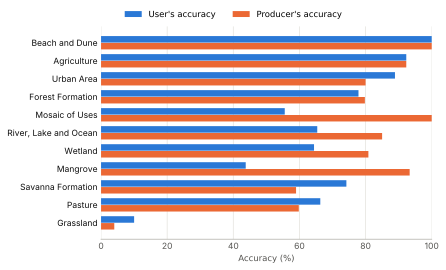

In [6]:
order = np.argsort(-(users + producers) / 2, kind="stable")[::-1]
names = [CLASSES[labels[i]][0] for i in order]
y = np.arange(len(order))
h = 0.36

fig, ax = plt.subplots(figsize=(6.3, 3.9))
ax.barh(y + h / 2 + 0.01, users[order] * 100, height=h, color="#2a78d6", label="User's accuracy")
ax.barh(y - h / 2 - 0.01, producers[order] * 100, height=h, color="#eb6834", label="Producer's accuracy")
ax.set_yticks(y, names)
ax.set_xlim(0, 100)
ax.set_xlabel("Accuracy (%)", color="#52514e", fontsize=8.5)
ax.xaxis.grid(True, color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color("#b5b4ad")
ax.tick_params(axis="both", labelsize=8.5, colors="#52514e", length=0)
ax.tick_params(axis="y", labelcolor="#0b0b0b")
ax.legend(loc="lower center", bbox_to_anchor=(0.4, 1.0), ncol=2, frameon=False, fontsize=8.5)
for t in ax.get_yticklabels() + ax.get_xticklabels():
    t.set_fontfamily(["Inter", "DejaVu Sans"])
fig.tight_layout()
display(HTML('<div class="caption"><b>Figure 1.</b> User\'s and producer\'s accuracy per class, '
             'ordered by their mean.</div>'))
plt.show()

### 3.2 Confusion matrix

Most errors involve the vegetation classes that dominate the region (Table 2). Forest Formation is confused mainly with Savanna Formation and Pasture, and it accounts for all of the over-mapping of Mangrove. Grassland reference samples were mapped mostly as Wetland (7), Pasture (6) and Savanna Formation (4).

In [7]:
head = "".join(f"<th>{c}</th>" for c in labels)
body = []
for i, c in enumerate(labels):
    cells = "".join(f"<td class='{'diag' if i == j else ''}'>{cm[i, j]}</td>" for j in range(len(labels)))
    body.append(f"<tr><th>{c}</th><td class='left'>{CLASSES[c][0]}</td>{cells}<td class='total'>{n_map[i]}</td></tr>")
foot = "".join(f"<td class='total'>{v}</td>" for v in n_ref)
body.append(f"<tr><th></th><td class='left total'>Total</td>{foot}<td class='total'>{n}</td></tr>")
display(HTML(f"""
<div class="caption"><b>Table 2.</b> Confusion matrix (number of samples). Rows: MapBiomas map; columns: reference.
Shaded cells are correctly classified samples.</div>
<table class="report-table">
<thead><tr><th>ID</th><th class="left">Map class</th>{head}<th>Total</th></tr></thead>
<tbody>{''.join(body)}</tbody>
</table>
<div class="source">Class IDs as in Table 1.</div>
"""))

ID,Map class,3,4,5,11,12,15,18,21,23,24,33,Total
3,Forest Formation,225,34,1,0,3,23,1,0,0,0,2,289
4,Savanna Formation,12,69,0,0,4,8,0,0,0,0,0,93
5,Mangrove,18,0,14,0,0,0,0,0,0,0,0,32
11,Wetland,8,0,0,38,7,6,0,0,0,0,0,59
12,Grassland,0,6,0,0,1,2,0,0,0,0,1,10
15,Pasture,16,4,0,3,6,61,0,0,0,2,0,92
18,Agriculture,0,0,0,0,0,1,12,0,0,0,0,13
21,Mosaic of Uses,1,4,0,0,3,0,0,10,0,0,0,18
23,Beach and Dune,0,0,0,0,0,0,0,0,14,0,0,14
24,Urban Area,0,0,0,0,0,1,0,0,0,8,0,9


### 3.3 Overall accuracy and comparison with Brazil

Overall accuracy in the study area was 71.6%, well below the 85.8% that MapBiomas reports for Brazil (Table 3). The larger share of the gap comes from allocation disagreement, 20.8% against 9.4% nationally: the maps get the proportions of the classes roughly right but place them in the wrong locations more often than in the country as a whole. The Kappa of 0.62 corresponds to substantial agreement (Landis and Koch, 1977). The comparison is only indicative, because the national figures are area-weighted estimates (Stehman, 2014) over a set of classes that differs from the one assessed here.

In [8]:
metrics = [
    ("Overall accuracy",          overall_accuracy,     BRAZIL["overall_accuracy"]),
    ("Overall error",             1 - overall_accuracy, BRAZIL["overall_error"]),
    ("Quantity disagreement",     quantity,             BRAZIL["quantity"]),
    ("Allocation disagreement",   allocation,           BRAZIL["allocation"]),
]
rows = "".join(f"<tr><td class='left'>{m}</td><td>{pct(a)}</td><td>{pct(b)}</td></tr>" for m, a, b in metrics)
rows += f"<tr><td class='left'>Cohen's Kappa</td><td>{kappa:.2f}</td><td>—</td></tr>"
display(HTML(f"""
<div class="caption"><b>Table 3.</b> Overall metrics for the study area and for Brazil.</div>
<table class="report-table" style="width:70%">
<thead><tr><th class="left">Metric</th><th>Study area (SA-23-Z)</th><th>Brazil (MapBiomas)</th></tr></thead>
<tbody>{rows}</tbody>
</table>
<div class="source">Study area: sample counts, 655 samples. Brazil: MapBiomas accuracy statistics for Collection 8 (MapBiomas, 2023),
area-weighted; MapBiomas does not report Kappa.</div>
"""))

Metric,Study area (SA-23-Z),Brazil (MapBiomas)
Overall accuracy,71.6%,85.8%
Overall error,28.4%,14.2%
Quantity disagreement,7.6%,4.8%
Allocation disagreement,20.8%,9.4%
Cohen's Kappa,0.62,—


### 3.4 Spatial distribution of disagreement

The 186 samples where the map and the reference disagree are spread over the whole chart group, without a visible concentration in any sub-region (Figure 2). This suggests that the errors are not driven by one problematic area, such as the coast or a single scene.

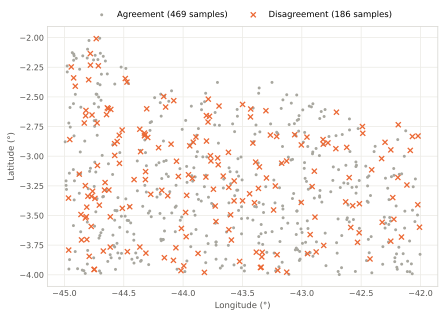

In [9]:
agree = df_acc["classification"] == df_acc["reference"]
fig, ax = plt.subplots(figsize=(6.3, 4.4))
ax.scatter(df_acc.loc[agree, "LON"], df_acc.loc[agree, "LAT"], s=9, color="#a8a79f",
           linewidths=0, label=f"Agreement ({int(agree.sum())} samples)")
ax.scatter(df_acc.loc[~agree, "LON"], df_acc.loc[~agree, "LAT"], s=26, marker="x", color="#eb6834",
           linewidths=1.3, label=f"Disagreement ({int((~agree).sum())} samples)")
ax.set_aspect("equal")
ax.set_xlabel("Longitude (°)", color="#52514e", fontsize=8.5)
ax.set_ylabel("Latitude (°)", color="#52514e", fontsize=8.5)
ax.grid(True, color="#ecebe6", linewidth=0.8)
ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_color("#d9d8d3")
ax.tick_params(labelsize=8, colors="#52514e", length=0)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False, fontsize=8.5)
fig.tight_layout()
display(HTML('<div class="caption"><b>Figure 2.</b> Validation samples in chart group SA-23-Z (WGS 84), by agreement '
             'between the MapBiomas map and the reference.</div>'))
plt.show()

## 4. Discussion and limitations

**Coastal classes.** Mangrove is reliable where the reference says Mangrove, but the map extends it into neighbouring forest, which inflates its area. Separating Mangrove from Forest Formation is a known difficulty and deserves more samples and review by interpreters who know the region. The perfect score for Beach and Dune rests on only 14 samples, all in the Lençóis Maranhenses, where the dunes are hard to confuse with other covers. Apicum, a class of interest in the region, could not be assessed at all.

**Grassland.** With a producer's accuracy of 4%, Grassland is the least accurate class in the study area, below the about 9% that MapBiomas reports for Brazil.

**Sample counts versus area.** All results above are computed from sample counts. An area-weighted estimate, computed in the analysis notebook from the inclusion probabilities of the samples, gives an overall accuracy of 75.6%. The national MapBiomas statistics are area-weighted, which is one more reason to read Table 3 as indicative.

**Training samples.** 82 of the 712 samples (69 of the 655 analysed) are flagged in the MapBiomas data as having been used to train the classifier. The MapBiomas assessment code is meant to discard them, but its filter does not match the label used in the data, so they remain in this analysis, as in the published article. Excluding them changes overall accuracy from 71.6% to 72.0% and does not change Kappa at two decimal places, so the conclusions hold.

**Representativeness.** The chart group covers about 72% of the region, and some classes have few samples. Per-class figures for classes with fewer than about 20 samples should be read with caution.

## 5. Conclusions

At legend level 2, MapBiomas Collection 8 reaches an overall accuracy of 71.6% in the São Luís intermediate region, with a Kappa of 0.62. This is substantial agreement, but clearly below the national figures, mostly because of allocation errors. The assessment adds accuracy figures for classes that MapBiomas does not report: Beach and Dune is mapped very reliably, while Mangrove is over-mapped at the expense of Forest Formation. A dedicated set of reference samples for the coast, validated by local experts, is needed to assess Mangrove, Apicum and Beach and Dune with more confidence.

## Reproducibility

Code, data and both notebooks are in [github.com/LambdaGeo/acuracia-slz](https://github.com/LambdaGeo/acuracia-slz) (MIT license for the code; the data derive from MapBiomas and follow its terms of use). With Python 3.12 and the pinned dependencies in `requirements.txt`, running `2_acuracia_sa23z.ipynb` reproduces the published results, and `python build_report.py` rebuilds this report. The report checks the values quoted in its text against the analysis and stops if they differ.

## References

<div class="refs">

Landis, J. R.; Koch, G. G. (1977). The measurement of observer agreement for categorical data. *Biometrics*, 33(1), 159–174. https://doi.org/10.2307/2529310

MapBiomas (2023). Projeto MapBiomas – Coleção 8 da Série Anual de Mapas de Cobertura e Uso da Terra do Brasil, 1985–2022. https://brasil.mapbiomas.org

Parente, L.; Mattos, A. P.; Baumann, L. et al. (2021). Shaping the Brazilian landscape: a process driven by land occupation, large-scale deforestation, and rapid agricultural expansion. *Research Square* (preprint). https://doi.org/10.21203/rs.3.rs-819697/v1

Pontius, R. G.; Millones, M. (2011). Death to Kappa: birth of quantity disagreement and allocation disagreement for accuracy assessment. *International Journal of Remote Sensing*, 32(15), 4407–4429. https://doi.org/10.1080/01431161.2011.552923

Rocha, T. V. S. M.; Costa, S. S.; Correia, L. F. C. S.; Bezerra, D. S. (2025). Avaliação da acurácia na classificação de uso e cobertura da terra: um estudo de caso na região intermediária de São Luís com o MapBiomas. *Geonordeste*, 36(2), 121–139. https://doi.org/10.33360/geonordeste.v36i.21680

Souza, C. M., Jr. et al. (2020). Reconstructing three decades of land use and land cover changes in Brazilian biomes with Landsat archive and Earth Engine. *Remote Sensing*, 12(17), 2735. https://doi.org/10.3390/rs12172735

Stehman, S. V. (2014). Estimating area and map accuracy for stratified random sampling when the strata are different from the map classes. *International Journal of Remote Sensing*, 35(13), 4923–4939. https://doi.org/10.1080/01431161.2014.930207

</div>